In [17]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt  
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd  
from cartopy.io.shapereader import Reader
import matplotlib.patheffects as pe

os.chdir ('C:\\Users\\hamod4691\\Code\\arctic-benthic-biodiversity\\All data')

# Merge

In [10]:
files = {
    "GBIF": "gbif_final.parquet",
    "OBIS": "obis_final.parquet",
    "CB": "cb_final.parquet",
    "OGSL": "ogsl_final.parquet",
}

dfs = [
    pd.read_parquet(os.path.join("..", folder, fname))
    for folder, fname in files.items()
 ]
all_merged = pd.concat(dfs, ignore_index=True)

# Keep mixed text/number values by normalizing to string
for col in ["sourceID", "eventID"]:
    if col in all_merged.columns:
        all_merged[col] = all_merged[col].apply(
            lambda x: x.decode("utf-8") if isinstance(x, (bytes, bytearray)) else x
        ).astype("string")

# Normalize percentCoverage to string to avoid mixed object types
if "percentCoverage" in all_merged.columns:
    all_merged["percentCoverage"] = all_merged["percentCoverage"].apply(
        lambda x: x.decode("utf-8") if isinstance(x, (bytes, bytearray)) else x
    ).astype("string")

# Clean and coerce percentCoverage to numeric in a new column
if "percentCoverage" in all_merged.columns:
    percent_clean = all_merged["percentCoverage"].astype("string").str.strip()
    percent_clean = percent_clean.str.replace("%", "", regex=False)
    percent_clean = percent_clean.str.replace(",", "", regex=False)
    all_merged["percentCoverage_num"] = pd.to_numeric(percent_clean, errors="coerce")

total_records = len(all_merged)
all_merged.to_parquet("all_merged.parquet", index=False)

total_records

3618137

# Visualize stations

In [11]:
stations = pd.read_parquet("all_merged.parquet")

cols = [
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "datasetKey",
    "datasetTitle",
    "sourceDatabase",
    "year",
    "gebcoDepth",
]
all_stations = stations[cols].drop_duplicates()

all_stations.to_parquet("all_stations.parquet", index=False)

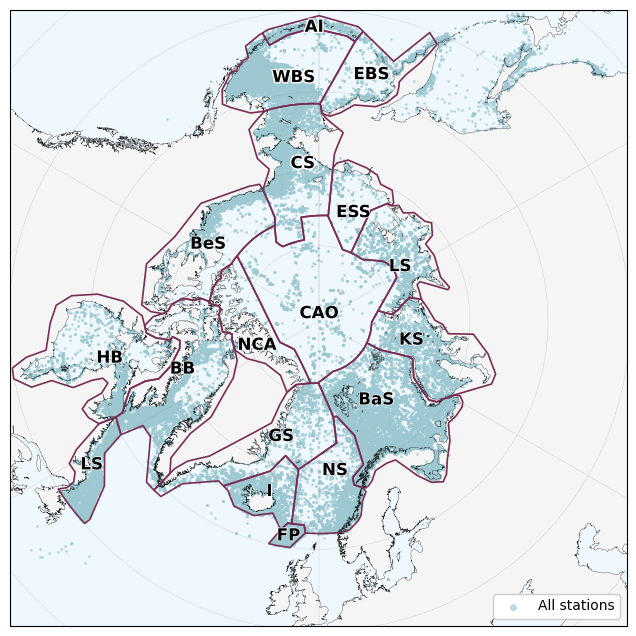

In [19]:
#| fig-pos: "H"
#| label: fig-map_stations
#| fig-cap: "An overview of the stations, with PANABIO stations in blue and HAUSGARTEN stations in red. The Arctic Large Marine Ecosystems (purple) define the main study area. The Large Marine Ecosystems are Labrador Sea (LS), Hudson Bay (HB), Baffin Bay (BB), Beaufort Sea (BeS), Chukchi Sea (CS), West Bering Sea (WBS), East Bering Sea (EBS), Aleutian Islands (AI), East Siberian Sea (ESS), Laptev Sea (LS), Kara Sea (KS), Barents Sea (BaS), Norwegian Sea (NS), Iceland (I), Faroe Plateau (FP), Greenland Sea (GS), North Canadian Archipelago (NCA) and Central Arctic Ocean (CAO). "
# Ensure shapefile can be read even if .shx is missing
os.environ['SHAPE_RESTORE_SHX'] = 'YES'

# Load the data from device_water.xlsx
FILEPATH = 'all_stations.parquet'
df_station = pd.read_parquet(FILEPATH)

# Use LatStart and LonStart for coordinates
lat = df_station['decimalLatitudeStart'].copy()
lon = df_station['decimalLongitudeStart'].copy()

# Create coordinates dataframe
coords = pd.DataFrame({
    'lat': pd.to_numeric(lat, errors='coerce'),
    'lon': pd.to_numeric(lon, errors='coerce')
})
coords = coords.dropna()

# Filter to plausible lat/lon ranges
coords = coords[(coords['lat'] >= -90) & (coords['lat'] <= 90) &
                (coords['lon'] >= -180) & (coords['lon'] <= 180)]


# Create the plot with smaller figure size
plt.figure(figsize=(8, 8))
proj = ccrs.NorthPolarStereo()
ax = plt.axes(projection=proj)
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.coastlines(resolution='10m', linewidth=0.2, color='black')
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')

# Add shapefile lines (EPSG:4326, same as stations)
shape_reader = Reader('../LME_boundaries_2014/lme_2013_wgs.shp')
line_feature = cfeature.ShapelyFeature(
    list(shape_reader.geometries()),
    ccrs.PlateCarree(),
    edgecolor='#792D54',
    facecolor='none'
)
ax.add_feature(line_feature, linewidth=1.2)

# Read the shapefile with attributes so we can access names
gdf_lme = gpd.read_file('../LME_boundaries_2014/lme_2013_wgs.shp')

# Ensure coordinates for labeling are in EPSG:4326 (PlateCarree)
gdf_lme_pc = gdf_lme.to_crs(epsg=4326)

# Step 1: Reproject to a projected CRS (e.g., EPSG:3395 for World Mercator)
gdf_lme_projected = gdf_lme.to_crs(epsg=3395)
# Step 2: Calculate centroids in the projected CRS
gdf_lme_projected['centroid'] = gdf_lme_projected.geometry.centroid
# Step 3: Reproject centroids back to the original geographic CRS (EPSG:4326)
gdf_lme_pc['centroid'] = gdf_lme_projected['centroid'].to_crs(epsg=4326)
# Step 4: Extract longitude and latitude for labeling
gdf_lme_pc['lon'] = gdf_lme_pc['centroid'].x  # Extract longitude
gdf_lme_pc['lat'] = gdf_lme_pc['centroid'].y  # Extract latitude


# Step 5: Add labels using the LME field
for _, row in gdf_lme_pc.iterrows():
    if row['LME'] in ['Central Arctic LME', 'Chukchi Sea LME', 'West Bering Sea LME', 'Alutian Islands LME']:
        # Skip these labels in the main loop
        continue
# Handle specific cases for Barents Sea and Beaufort Sea
    if row['LME'] == 'Barents Sea LME':
        short_label = 'BaS'  # Unique abbreviation for Barents Sea
    elif row['LME'] == 'Beaufort Sea LME':
        short_label = 'BeS'  # Unique abbreviation for Beaufort Sea
    else:
        words = row['LME'].split()  # Split the name into words
        short_label = ''.join([word[0] for word in words[:-1]])  # Take the first letter of each word except the last one
    # Add the label to the map
    ax.text(
        row['lon'],
        row['lat'],
        short_label,  # Use the shortened label
        transform=ccrs.PlateCarree(),
        fontsize=12,
        fontweight='bold',  # Make the text bold
        color='black',
        ha='center',
        va='center',
        path_effects=[pe.withStroke(linewidth=1, foreground='white')]
    )

# Step 7: Manual adjustment for problematic labels
for _, row in gdf_lme_pc.iterrows():
    if row['LME'] == 'Central Arctic LME':
        ax.text(
            -179, 89,  # Replace with correct longitude and latitude
            'CAO',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=1, foreground='white')]
        )
    elif row['LME'] == 'Chukchi Sea LME':
        ax.text(
            -174, 69,  # Replace with correct longitude and latitude
            'CS',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )
    elif row['LME'] == 'West Bering Sea LME':
        ax.text(
            -174, 58,  # Replace with correct longitude and latitude
            'WBS',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )
    elif row['LME'] == 'Alutian Islands LME':
        ax.text(
            -179, 52,  # Replace with correct longitude and latitude
            'AI',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )

# Plot the station points
ax.scatter(coords['lon'].values, coords['lat'].values,
           s=1, color='#9DC8D2', alpha=0.6, transform=ccrs.PlateCarree(), label='All stations')


# Add a legend with a custom markerscale
plt.legend(loc='lower right', markerscale=4, fontsize=10, facecolor='white', framealpha=1)

plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()